# EDA: VC Deal Flow Signal

For this assignment I picked the [VC Deal Flow Signal](https://huggingface.co/datasets/the-data-nerd/vc-deal-flow-signal)
dataset from the finance section of [Awesome Public Datasets](https://github.com/awesomedata/awesome-public-datasets#finance).
It tracks GitHub activity for 55 startups over four quarters (Q3 2025 to Q2 2026). The idea is that a jump in engineering
activity can be an early hint that a startup is about to raise money.

The file has 219 rows and 13 columns:

- **Numerical (5):** `commit_velocity_14d`, `commit_velocity_change_pct`, `contributors`, `contributor_growth_pct`, `new_repos`
- **Categorical (5):** `period`, `stage`, `geography`, `sector_name`, `signal_type`
- **IDs (3):** `startup_name`, `github_url`, `sector_slug`

I followed the approach in the [NIST EDA handbook](https://www.itl.nist.gov/div898/handbook/eda/eda.htm): look at the data
mostly through plots, one variable at a time first and then in pairs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

## Loading the data

In [2]:
# local copy of startup_signals.csv from the Hugging Face dataset
df = pd.read_csv("data/startup_signals.csv")
print(df.shape)
df.head()

(219, 13)


,period,sector_slug,sector_name,startup_name,stage,geography,commit_velocity_14d,commit_velocity_change_pct,contributors,contributor_growth_pct,new_repos,signal_type,github_url
0,q2-2026,ai-ml,AI & Machine Learning,paperless-ngx,Growth,Unknown,54,-10,100,0,0,Framework migration,https://github.com/paperless-ngx
1,q2-2026,ai-ml,AI & Machine Learning,harvard-edge,Growth,Unknown,337,-30,95,13,1,Framework migration,https://github.com/harvard-edge
2,q2-2026,ai-ml,AI & Machine Learning,roboflow,Growth,US,24,-60,90,0,2,Framework migration,https://github.com/roboflow
3,q1-2026,ai-ml,AI & Machine Learning,paperless-ngx,Growth,Unknown,61,336,100,0,0,Deploy frequency spike,https://github.com/paperless-ngx
4,q1-2026,ai-ml,AI & Machine Learning,harvard-edge,Growth,Unknown,367,63,95,13,1,Framework migration,https://github.com/harvard-edge


In [3]:
print(df.isna().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")
print(df["startup_name"].nunique(), "startups")
df.dtypes

0 missing values
0 duplicate rows
55 startups


period                        object
sector_slug                   object
sector_name                   object
startup_name                  object
stage                         object
geography                     object
commit_velocity_14d            int64
commit_velocity_change_pct     int64
contributors                   int64
contributor_growth_pct         int64
new_repos                      int64
signal_type                   object
github_url                    object
dtype: object

No missing values or duplicates. One thing to keep in mind is that most startups show up four times (once per quarter),
so the rows aren't fully independent, and a big company like ClickHouse gets counted four times.

In [4]:
num_cols = ["commit_velocity_14d", "commit_velocity_change_pct", "contributors",
            "contributor_growth_pct", "new_repos"]

periods = ["q3-2025", "q4-2025", "q1-2026", "q2-2026"]
stages = ["Pre-seed", "Seed", "Series A/B", "Growth"]
df["period"] = pd.Categorical(df["period"], periods, ordered=True)
df["stage"] = pd.Categorical(df["stage"], stages, ordered=True)

signal_colors = {"Framework migration": "tab:blue", "Deploy frequency spike": "tab:orange",
                 "Engineering hiring burst": "tab:red", "Infrastructure buildout": "tab:green"}

## Summary statistics

For outliers I used the usual box plot rule: anything below Q1 - 1.5·IQR or above Q3 + 1.5·IQR.

In [5]:
def outlier_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

stats = df[num_cols].agg(["min", "max", "mean", "median", "std", "skew"]).T
bounds = df[num_cols].apply(outlier_bounds).T
stats["lower"], stats["upper"] = bounds[0], bounds[1]
stats["n_outliers"] = [((df[c] < stats.loc[c, "lower"]) | (df[c] > stats.loc[c, "upper"])).sum() for c in num_cols]
stats.round(2)

,min,max,mean,median,std,skew,lower,upper,n_outliers
commit_velocity_14d,1.0,2184.0,173.46,71.0,306.87,4.28,-216.75,425.25,20
commit_velocity_change_pct,-94.0,1647.0,96.04,-1.0,284.14,3.18,-170.75,207.25,29
contributors,3.0,100.0,68.08,89.0,35.83,-0.52,-81.25,208.75,0
contributor_growth_pct,0.0,240.0,19.99,0.0,52.88,3.25,-13.50,22.50,36
new_repos,0.0,4.0,0.47,0.0,0.83,2.21,-1.50,2.50,8


## Histograms of the numerical variables

In [6]:
def plot_hist(col, ax, log=False, **kwargs):
    s = df[col]
    x = np.log10(s) if log else s
    f = np.log10 if log else (lambda v: v)
    sns.histplot(x, ax=ax, color="steelblue", **kwargs)
    ax.axvline(f(s.mean()), color="red", ls="--", label=f"mean = {s.mean():.1f}")
    ax.axvline(f(s.median()), color="black", label=f"median = {s.median():.1f}")
    ax.set_xlabel(f"log10({col})" if log else col)
    ax.legend()

def show_outliers(col):
    lo, hi = outlier_bounds(df[col])
    out = df[(df[col] < lo) | (df[col] > hi)]
    print(f"{len(out)} outliers (outside {lo:.2f} to {hi:.2f})")
    if len(out):
        print(out["startup_name"].value_counts().to_dict())

### commit_velocity_14d

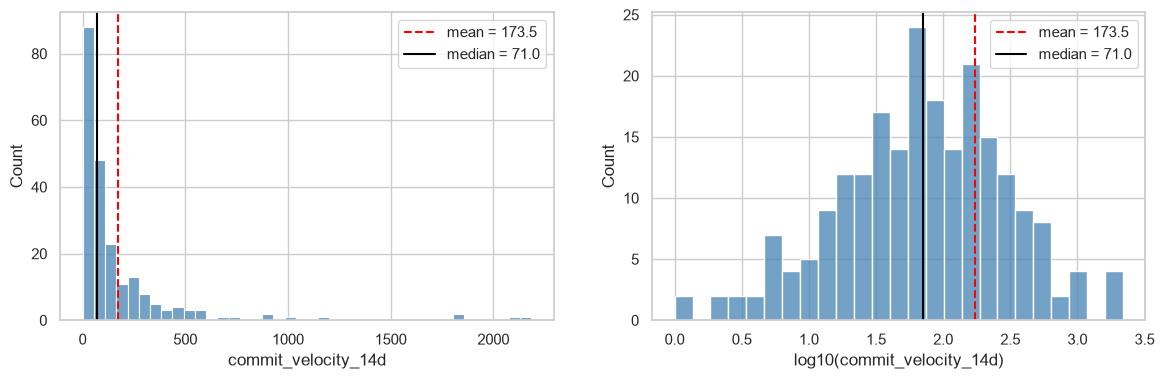

20 outliers (outside -216.75 to 425.25)
{'projectdiscovery': 4, 'ClickHouse': 4, 'bakaphp': 4, 'airbytehq': 3, 'mdn': 2, 'dbt-labs': 2, 'zapplyjobs': 1}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_hist("commit_velocity_14d", axes[0], bins=40)
plot_hist("commit_velocity_14d", axes[1], log=True, bins=25)
plt.show()
show_outliers("commit_velocity_14d")

Min 1, max 2184, mean 173.5, median 71. Very right-skewed: most startups make well under 200 commits in two weeks, but a
few go way past that. On a log scale (right) it looks pretty close to normal. There are 20 outliers above 425, which come
from just 7 companies (ClickHouse is the biggest at around 2000). I kept them since they're real companies, not errors. The
mean gets pulled up a lot by them, so the median is a better "typical" value here.

### commit_velocity_change_pct

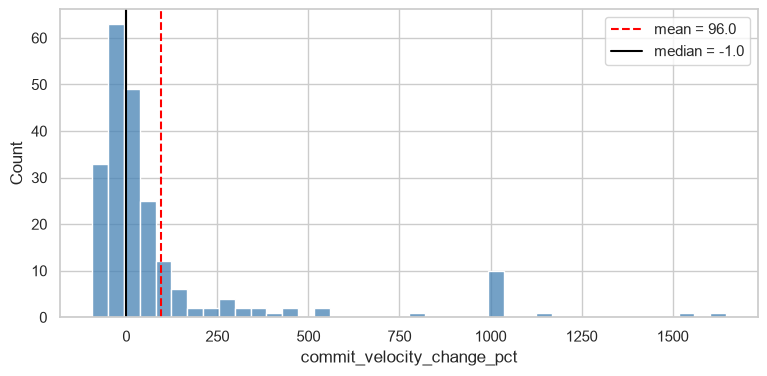

29 outliers (outside -170.75 to 207.25)
{'castle-engine': 2, 'zapplyjobs': 2, 'paperless-ngx': 1, 'polarsource': 1, 'orbiternassp': 1, 'ohrrpgce': 1, 'LiteFarmOrg': 1, 'ihmcrobotics': 1, 'debezium': 1, 'airbytehq': 1, 'dbt-labs': 1, 'PostHog': 1, 'ParabolInc': 1, 'vuestorefront': 1, 'opennem': 1, 'particify': 1, 'NDLANO': 1, 'OpenOLAT': 1, 'hpi-schul-cloud': 1, 'hapifhir': 1, 'ballerina-platform': 1, 'third-culture-software': 1, 'andes': 1, 'fleetdm': 1, 'OpenCTI-Platform': 1, 'cilium': 1, 'nextcloud': 1}
10 rows are exactly 999


In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_hist("commit_velocity_change_pct", ax, bins=40)
plt.show()
show_outliers("commit_velocity_change_pct")
print((df["commit_velocity_change_pct"] == 999).sum(), "rows are exactly 999")

Min -94%, max 1647%, mean 96%, median -1%. So the typical startup's activity barely changed, and the high mean comes from a
handful of big jumps. There are 29 outliers, all on the high end (221% and up), spread across lots of different startups.
Something odd: 10 rows are exactly 999%. That's probably a cap the data collector uses when the previous period had almost
no commits, so I wouldn't read those as exact values.

### contributors

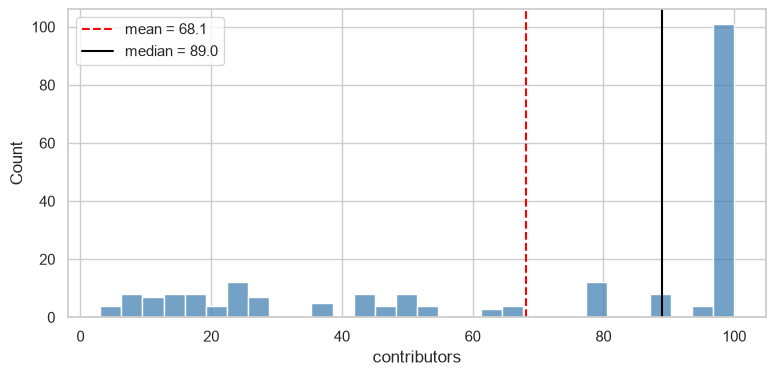

0 outliers (outside -81.25 to 208.75)
97 rows are exactly 100


In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_hist("contributors", ax, bins=30)
plt.show()
show_outliers("contributors")
print((df["contributors"] == 100).sum(), "rows are exactly 100")

Min 3, max 100, mean 68.1, median 89. No outliers by the IQR rule. The big spike at exactly 100 (97 rows) looks like the
value is capped at 100, probably a limit on how many contributors were pulled from GitHub. So for the bigger companies
the real number is "100 or more", and the mean and median are underestimates.

### contributor_growth_pct

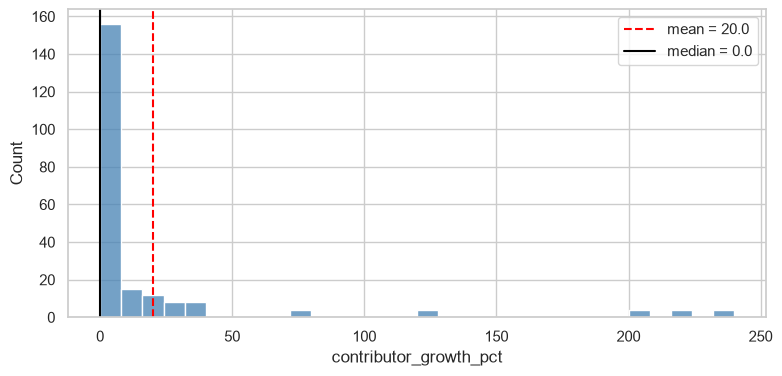

36 outliers (outside -13.50 to 22.50)
{'opennem': 4, 'nco': 4, 'hapifhir': 4, 'OpenOLAT': 4, 'debezium': 4, 'zapplyjobs': 4, 'betagouv': 4, 'FlaxEngine': 4, 'ohrrpgce': 4}


In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_hist("contributor_growth_pct", ax, bins=30)
plt.show()
show_outliers("contributor_growth_pct")

Min 0%, max 240%, mean 20%, median 0%. About two thirds of the rows are exactly 0, and there are no negative values. 36
rows are flagged as outliers (25% and up), but they all come from 9 startups that have the same value in all four
quarters. With this many zeros the IQR rule flags almost anything above zero, so these are really just small teams
that are growing.

### new_repos

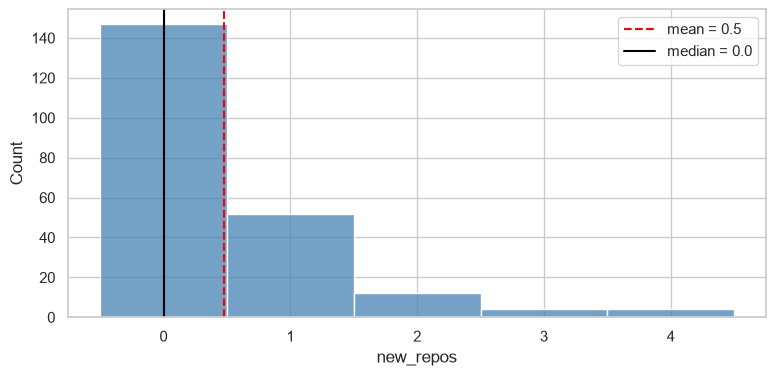

8 outliers (outside -1.50 to 2.50)
{'PostHog': 4, 'ClickHouse': 4}


In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_hist("new_repos", ax, discrete=True)
plt.show()
show_outliers("new_repos")

Min 0, max 4, mean 0.47, median 0. It's a small count: 147 rows have no new repos and 52 have one. The 8 outliers
(3 or 4 new repos) are just PostHog and ClickHouse in every quarter.

## Bar charts of the categorical variables

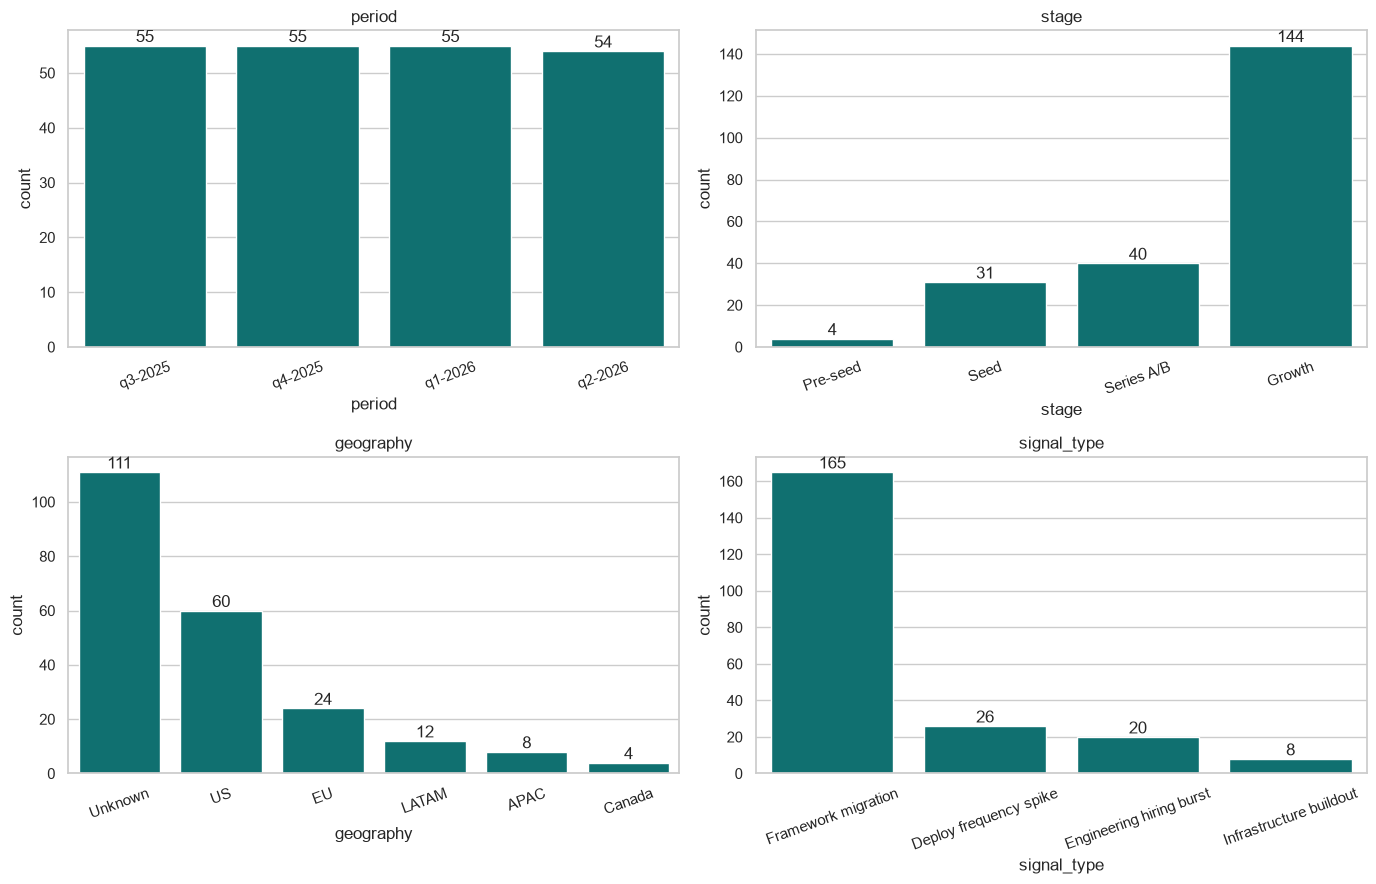

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, ["period", "stage", "geography", "signal_type"]):
    order = df[col].cat.categories if hasattr(df[col], "cat") else df[col].value_counts().index
    sns.countplot(x=df[col], order=order, ax=ax, color="teal")
    ax.bar_label(ax.containers[0])
    ax.tick_params(axis="x", rotation=20)
    ax.set_title(col)
plt.tight_layout()
plt.show()

- **period:** basically even (54-55 per quarter), since the same companies are tracked every quarter.
- **stage:** mostly Growth (144). Pre-seed only has 4 rows, and they're all the same startup.
- **geography:** about half the rows are "Unknown" (111), so I can't say much about region.
- **signal_type:** Framework migration is 75% of the data. Infrastructure buildout only has 8 rows.

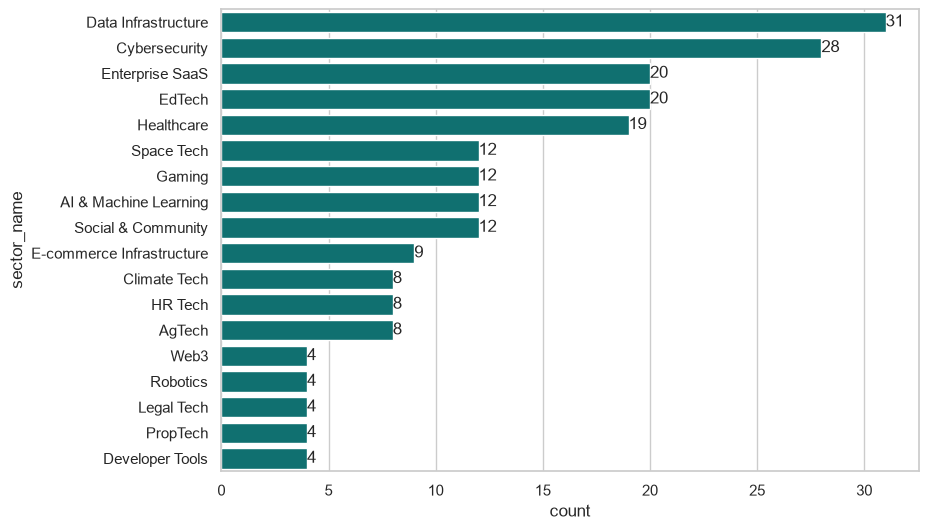

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.countplot(y=df["sector_name"], order=df["sector_name"].value_counts().index, ax=ax, color="teal")
ax.bar_label(ax.containers[0])
plt.show()

18 sectors. Data Infrastructure (31) and Cybersecurity (28) are the biggest. Five sectors only have 4 rows, which means
one startup each. I didn't plot `startup_name`, `github_url` or `sector_slug` since they're just IDs (about 4 rows per
startup).

## All numerical variables in one box plot

The variables are on really different scales (commits go up to 2184, new repos max out at 4), so I made two versions:
one with the raw values on a log-style axis, and one where each variable is standardized to z-scores.

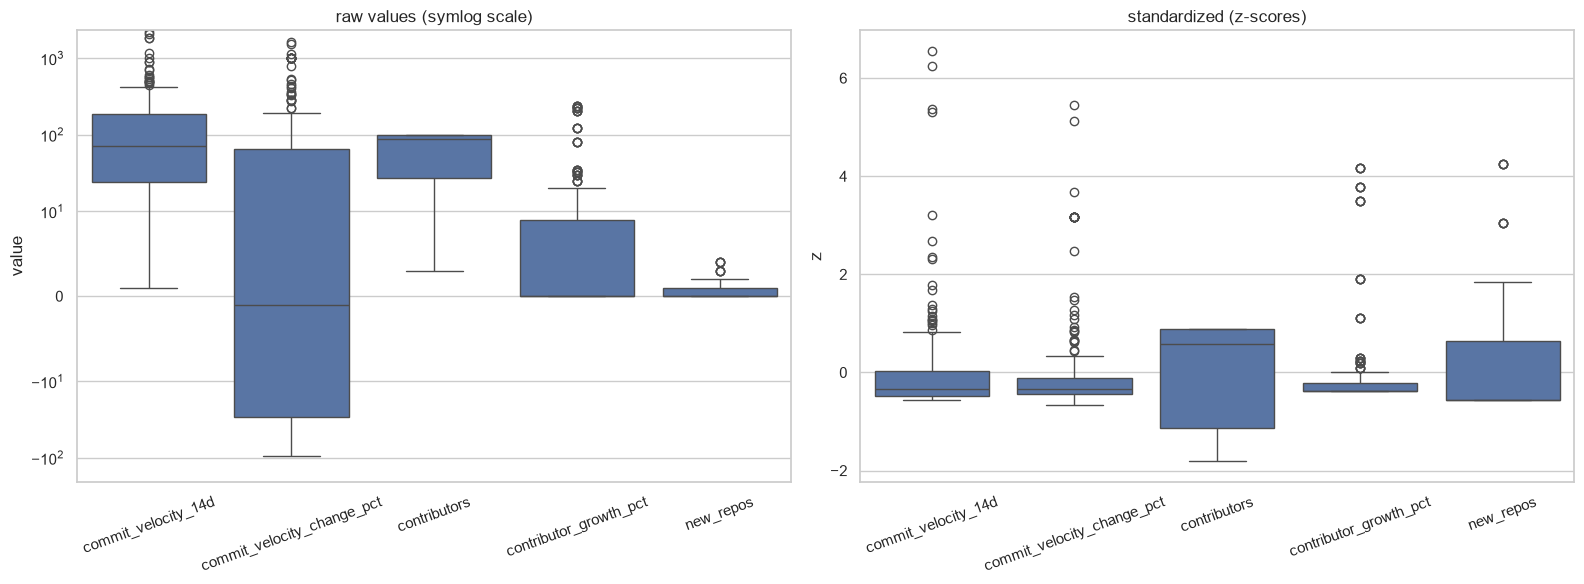

In [14]:
raw = df[num_cols].melt(var_name="variable", value_name="value")
z = ((df[num_cols] - df[num_cols].mean()) / df[num_cols].std()).melt(var_name="variable", value_name="z")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=raw, x="variable", y="value", ax=axes[0])
axes[0].set_yscale("symlog", linthresh=10)
axes[0].set_title("raw values (symlog scale)")
sns.boxplot(data=z, x="variable", y="z", ax=axes[1])
axes[1].set_title("standardized (z-scores)")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Side by side, four of the five variables are right-skewed with all their outliers on the high side. Contributors is the
odd one out: it's skewed left and runs right up to the 100 cap. ClickHouse sits more than 6 standard deviations above the
mean for commit velocity, so these definitely aren't normal distributions.

## Scatter plot matrix (numerical variables)

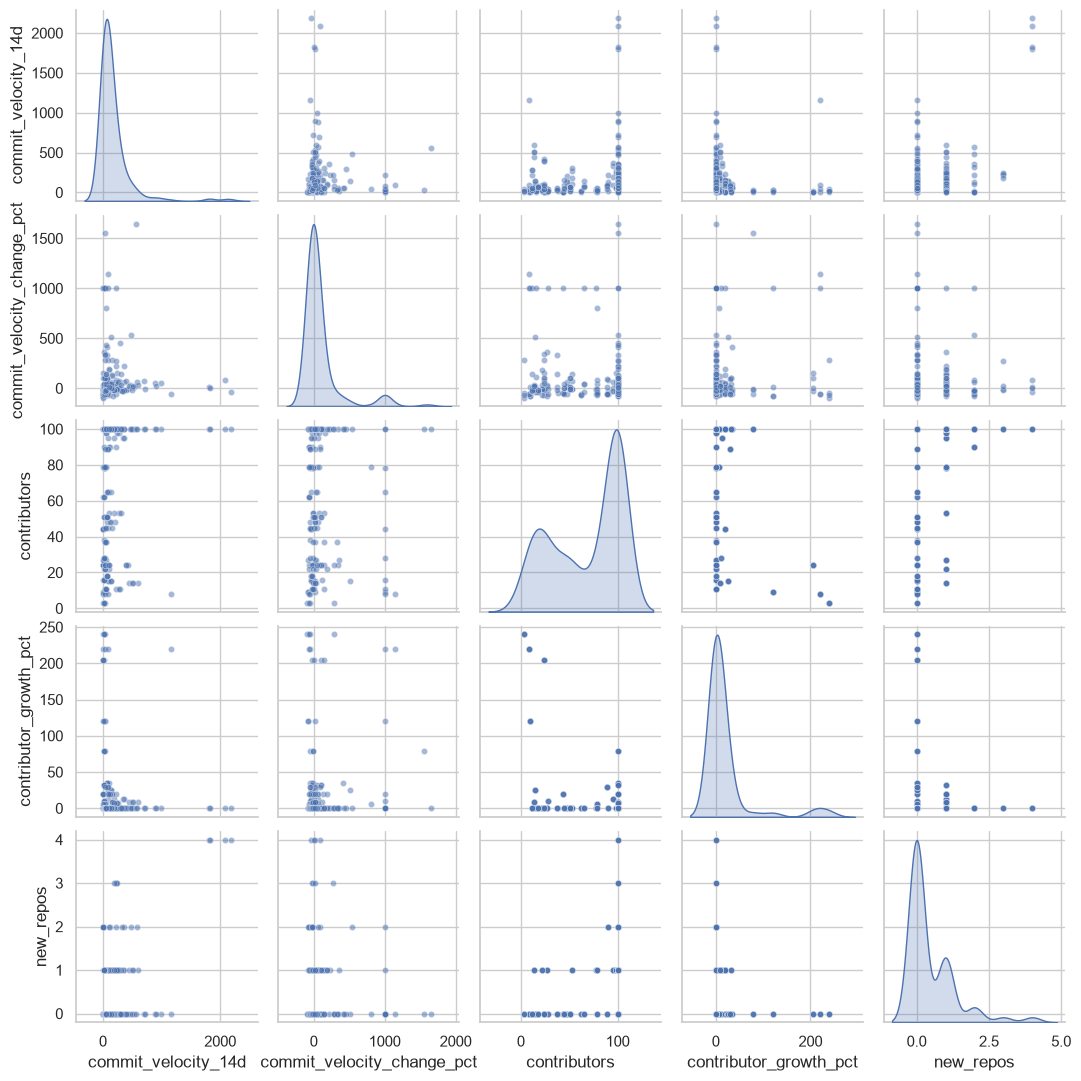

In [15]:
sns.pairplot(df[num_cols], diag_kind="kde", plot_kws={"alpha": 0.5, "s": 20}, height=2.2)
plt.show()

Velocity squashes everything into the corner, so here's the same thing with velocity on a log scale:

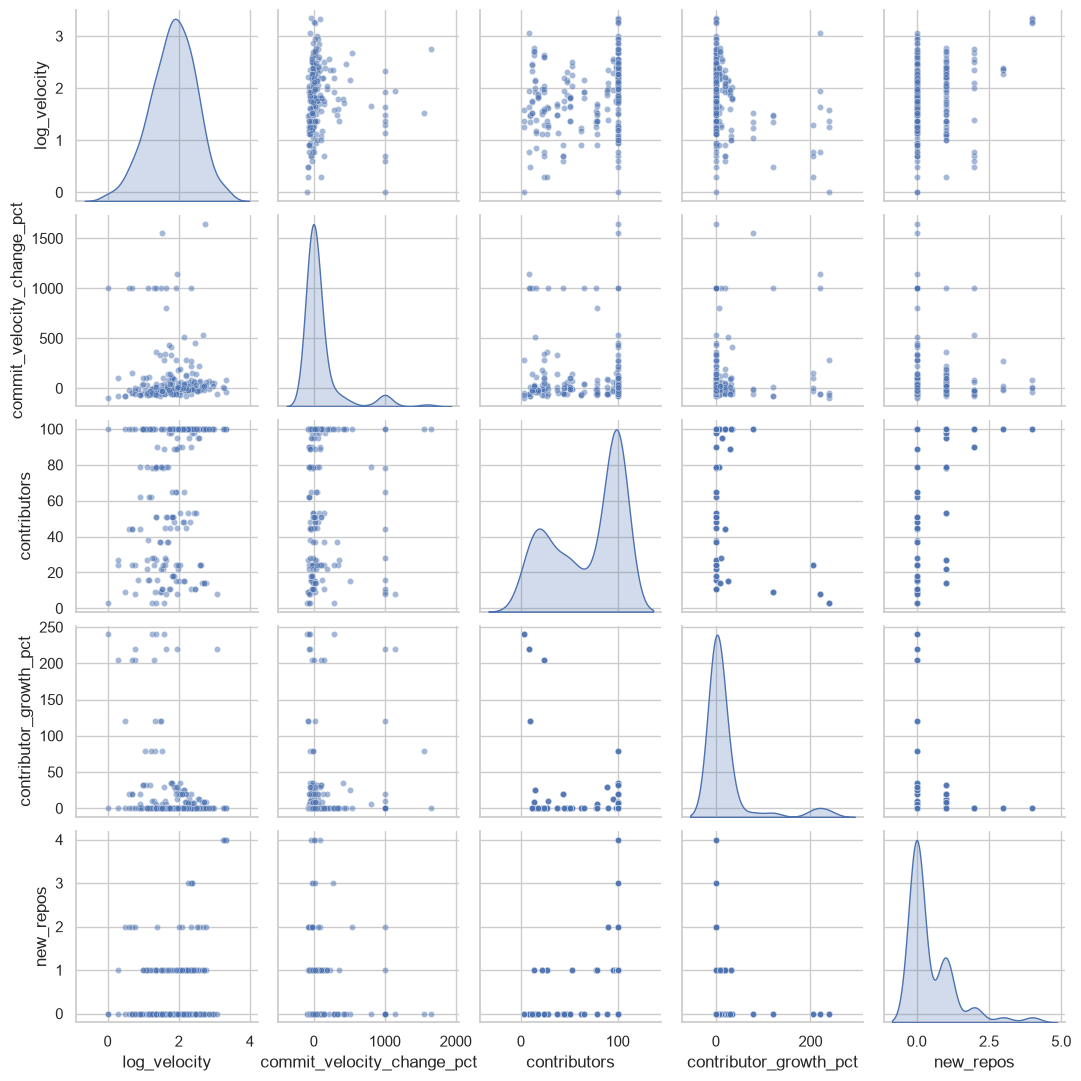

In [16]:
logged = df[num_cols].copy()
logged["commit_velocity_14d"] = np.log10(logged["commit_velocity_14d"])
logged = logged.rename(columns={"commit_velocity_14d": "log_velocity"})
sns.pairplot(logged, diag_kind="kde", plot_kws={"alpha": 0.5, "s": 20}, height=2.2)
plt.show()

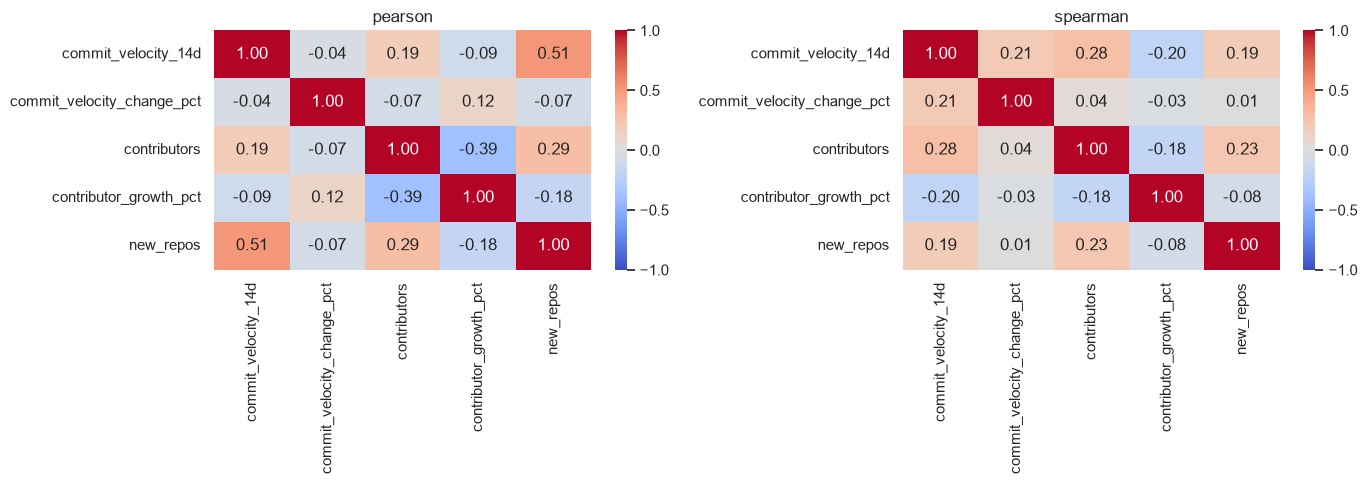

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[num_cols].corr(method=method), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, ax=ax)
    ax.set_title(method)
plt.tight_layout()
plt.show()

Nothing is strongly related. The largest Pearson correlation is velocity vs new repos (0.51), but in the scatter plot
that's mostly ClickHouse sitting in the top corner, and the Spearman (rank) correlation is only 0.19. Contributors vs
contributor growth is -0.39: the big teams at the 100 cap all have 0% growth. Velocity change % doesn't really relate to
anything else.

## Categorical vs categorical

You can't scatter two categorical variables, so I counted how often each combination shows up (a crosstab) and
plotted it as a heatmap. I also made a 100% stacked bar so groups of different sizes can be compared.

In [18]:
pd.crosstab(df["stage"], df["geography"], margins=True)

geography,APAC,Canada,EU,LATAM,US,Unknown,All
stage,,,,,,,
Pre-seed,0,0,0,0,0,4,4
Seed,4,0,12,4,4,7,31
Series A/B,0,0,4,0,4,32,40
Growth,4,4,8,8,52,68,144
All,8,4,24,12,60,111,219


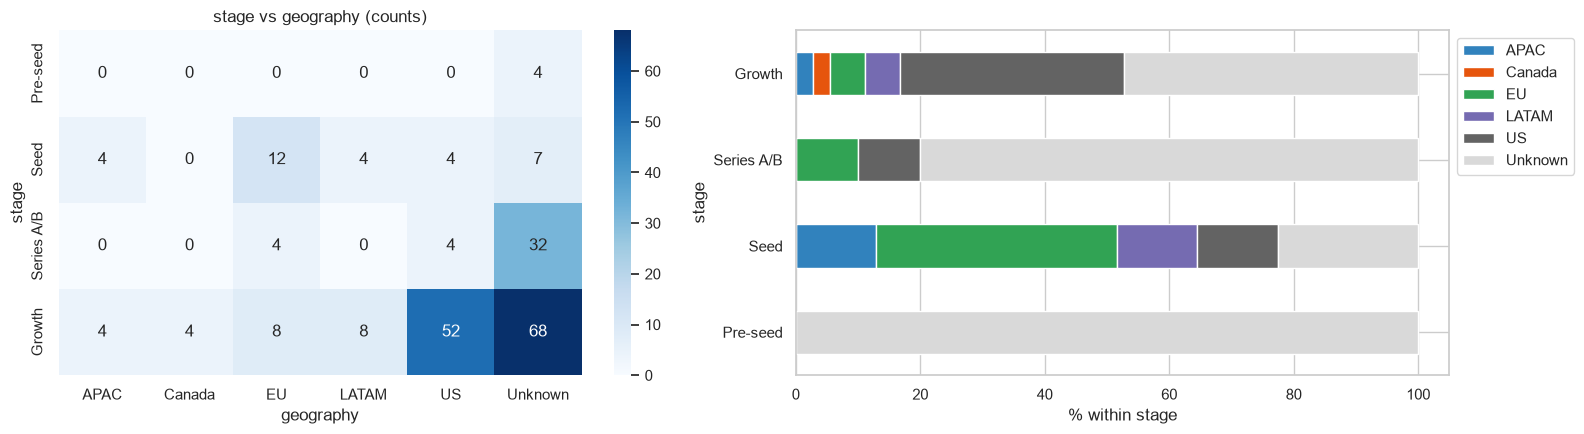

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.heatmap(pd.crosstab(df["stage"], df["geography"]), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("stage vs geography (counts)")
(pd.crosstab(df["stage"], df["geography"], normalize="index") * 100).plot(
    kind="barh", stacked=True, ax=axes[1], colormap="tab20c")
axes[1].set_xlabel("% within stage")
axes[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Among Growth companies with a known region, most are in the US (52 of 76). Seed is the only stage where the EU leads (12
of 31). Series A/B is 80% Unknown, so the missing geography data makes this hard to interpret.

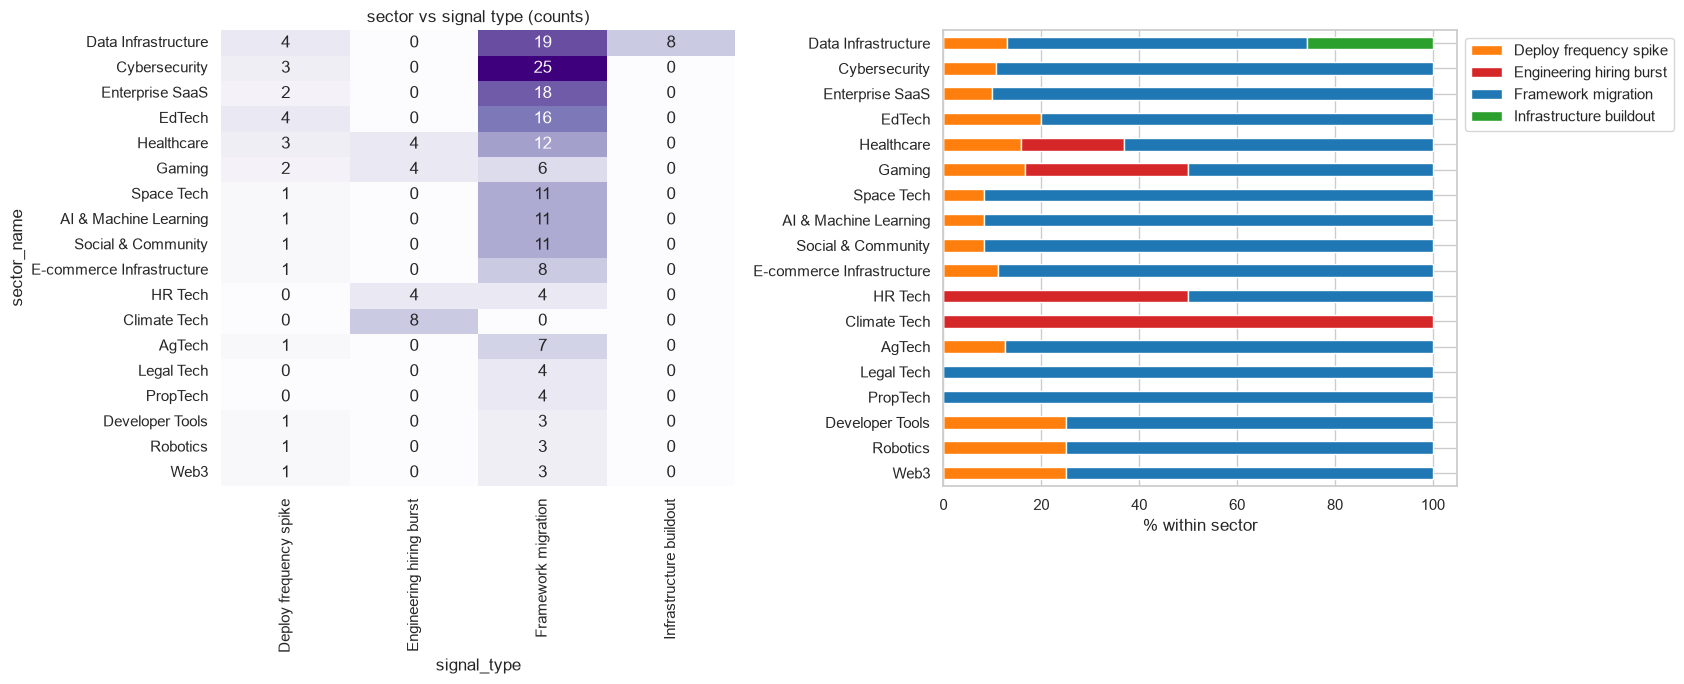

In [20]:
ct = pd.crosstab(df["sector_name"], df["signal_type"])
order = ct.sum(axis=1).sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.heatmap(ct.loc[order[::-1]], annot=True, fmt="d", cmap="Purples", cbar=False, ax=axes[0])
axes[0].set_title("sector vs signal type (counts)")
(pd.crosstab(df["sector_name"], df["signal_type"], normalize="index") * 100).loc[order].plot(
    kind="barh", stacked=True, ax=axes[1], color=signal_colors)
axes[1].set_xlabel("% within sector")
axes[1].set_ylabel("")
axes[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Framework migration is the most common signal in almost every sector. Climate Tech is the exception: all 8 of its rows
are Engineering hiring burst. Infrastructure buildout only shows up in Data Infrastructure. Most sectors are only one to
three companies though, so I wouldn't generalize from this.

### Aggregating one variable by another

Here I group by sector and look at commit velocity. I used the median as well as the mean because of the outliers.

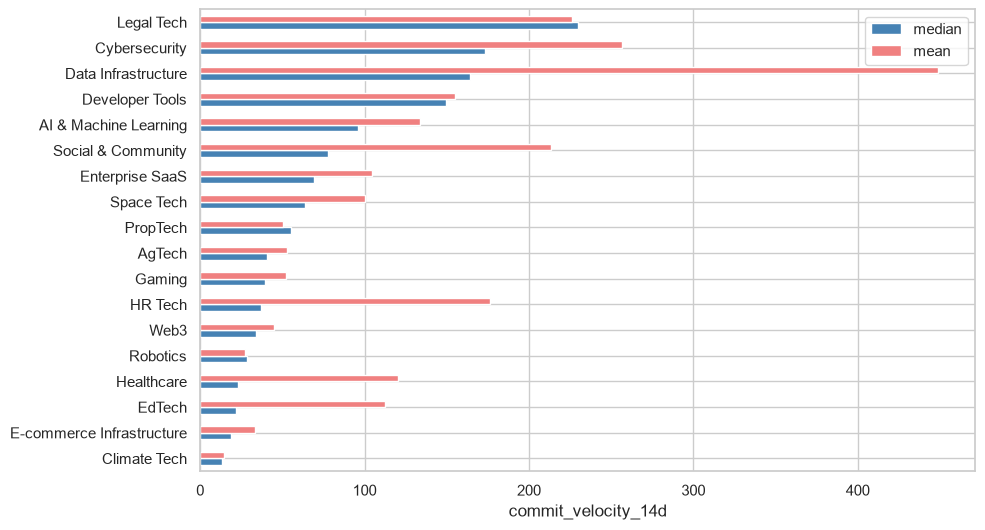

,count,mean,median
sector_name,,,
Climate Tech,8,14.8,13.0
E-commerce Infrastructure,9,33.1,19.0
EdTech,20,112.2,22.0
Healthcare,19,120.4,23.0
Robotics,4,27.5,28.5
Web3,4,44.8,34.0
HR Tech,8,176.4,37.0
Gaming,12,52.1,39.5
AgTech,8,52.9,40.5


In [21]:
by_sector = df.groupby("sector_name")["commit_velocity_14d"].agg(["count", "mean", "median"]).sort_values("median")

fig, ax = plt.subplots(figsize=(10, 6))
by_sector[["median", "mean"]].plot(kind="barh", ax=ax, color=["steelblue", "lightcoral"])
ax.set_xlabel("commit_velocity_14d")
ax.set_ylabel("")
plt.show()
by_sector.round(1)

Legal Tech (230), Cybersecurity (173.5) and Data Infrastructure (164) have the highest median velocity. Climate Tech (13)
has the lowest. Data Infrastructure's mean (449) is way higher than its median because ClickHouse is in that sector.

## Categorical vs numerical

Two ways to show this: box plots of a numerical variable split by category, and scatter plots with the category shown
as color.

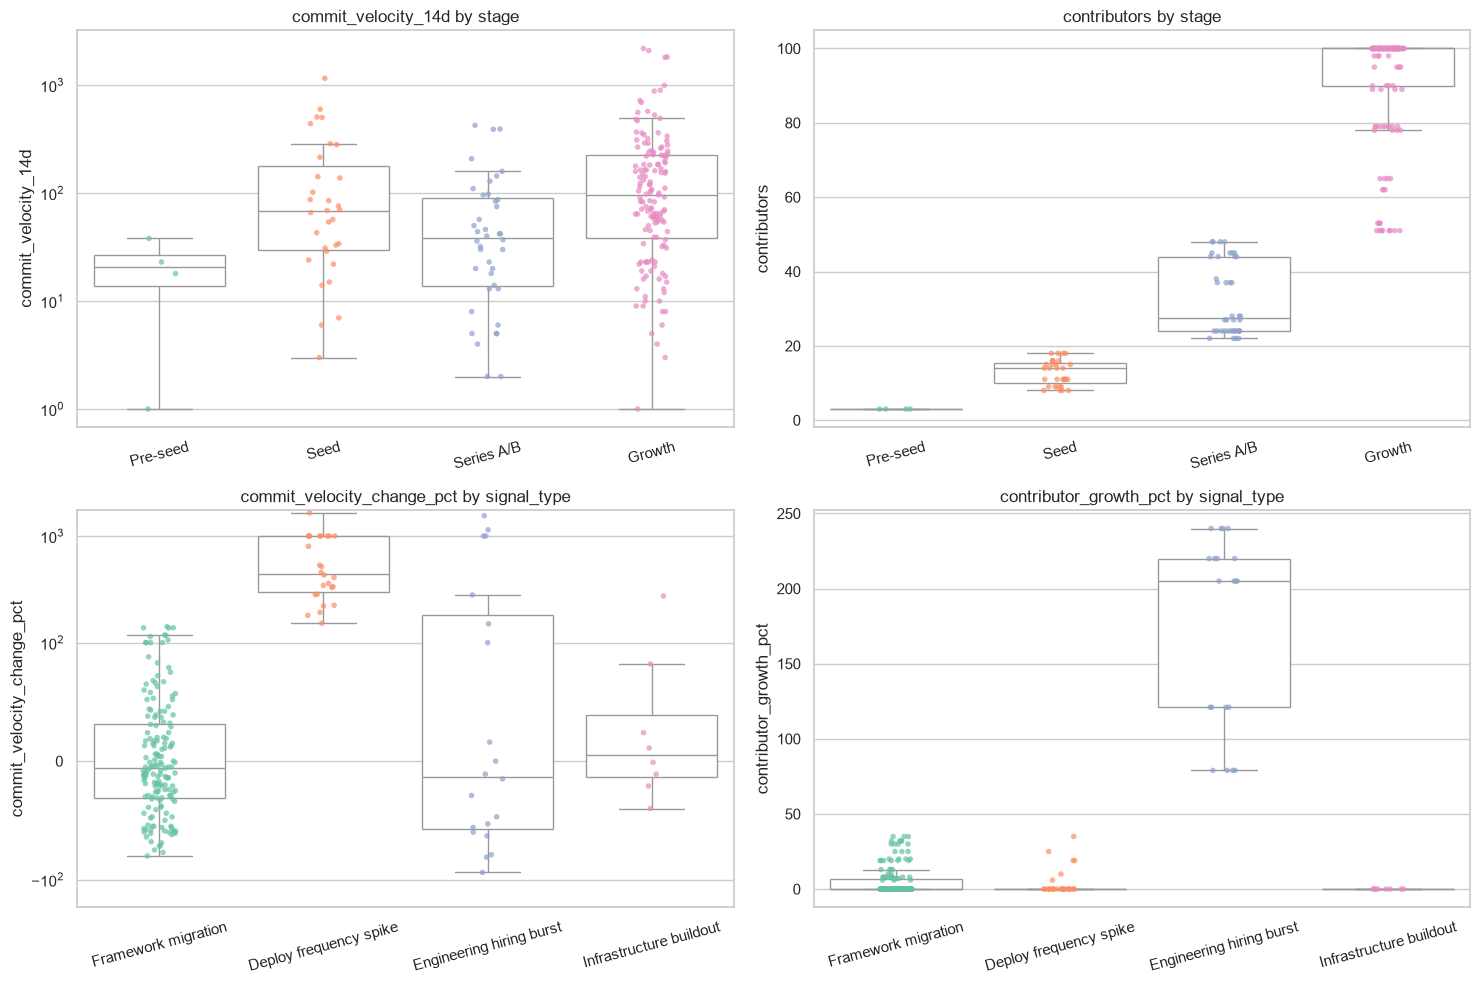

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
pairs = [("stage", "commit_velocity_14d"), ("stage", "contributors"),
         ("signal_type", "commit_velocity_change_pct"), ("signal_type", "contributor_growth_pct")]
for ax, (cat, num) in zip(axes.flat, pairs):
    sns.boxplot(data=df, x=cat, y=num, ax=ax, color="white", showfliers=False)
    sns.stripplot(data=df, x=cat, y=num, ax=ax, hue=cat, palette="Set2", alpha=0.7, size=4, legend=False)
    if num == "commit_velocity_14d":
        ax.set_yscale("log")
    if num == "commit_velocity_change_pct":
        ax.set_yscale("symlog", linthresh=100)
    ax.tick_params(axis="x", rotation=15)
    ax.set_xlabel("")
    ax.set_title(f"{num} by {cat}")
plt.tight_layout()
plt.show()

In [23]:
df.groupby("stage", observed=True)[["commit_velocity_14d", "contributors"]].median()

,commit_velocity_14d,contributors
stage,,
Pre-seed,20.5,3.0
Seed,69.0,14.0
Series A/B,38.5,27.5
Growth,97.0,100.0


In [24]:
df.groupby("signal_type")[["commit_velocity_change_pct", "contributor_growth_pct"]].median()

,commit_velocity_change_pct,contributor_growth_pct
signal_type,,
Deploy frequency spike,443.0,0.0
Engineering hiring burst,-13.0,205.0
Framework migration,-6.0,0.0
Infrastructure buildout,5.0,0.0


- Stage lines up very clearly with team size: median contributors go 3 → 14 → 27.5 → 100 from Pre-seed to Growth.
- Growth companies have the highest median velocity (97), but the spread inside each stage is huge.
- The signal labels match the numbers. Deploy frequency spike has a median velocity change of +443% (every other signal
  is between -13% and +5%), and Engineering hiring burst has a median contributor growth of 205% (every other signal is 0).

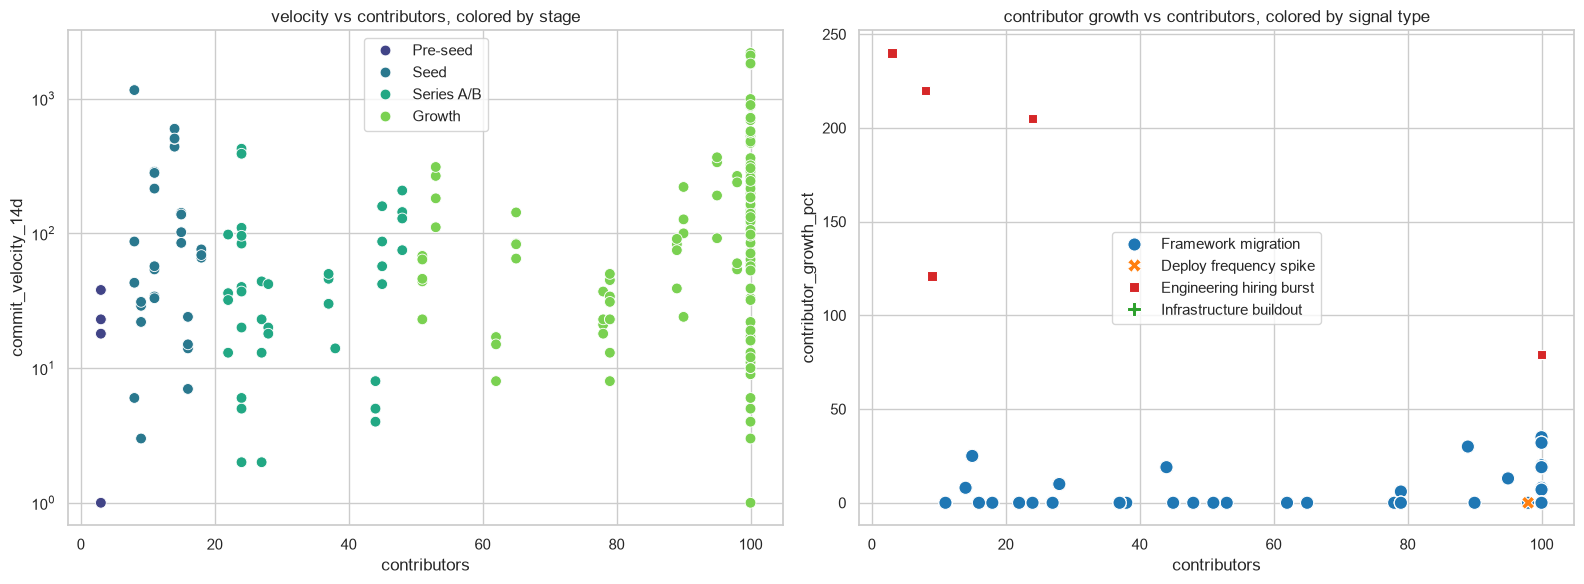

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=df, x="contributors", y="commit_velocity_14d", hue="stage", palette="viridis", s=60, ax=axes[0])
axes[0].set_yscale("log")
axes[0].legend(loc="upper center")
axes[0].set_title("velocity vs contributors, colored by stage")

sns.scatterplot(data=df, x="contributors", y="contributor_growth_pct", hue="signal_type",
                style="signal_type", palette=signal_colors, s=90, ax=axes[1])
axes[1].legend(loc="center")
axes[1].set_title("contributor growth vs contributors, colored by signal type")
plt.tight_layout()
plt.show()

On the left, the colors separate along the x-axis. Growth companies (light green) are bunched at the 100 cap and early-stage
ones are on the left, so a lot of the contributors/velocity relationship is really about stage. On the right, the red
hiring-burst points are clearly separated from everything else, and all but one of them are small teams. That
explains the negative correlation between contributors and contributor growth.

## Conclusions

- The data is clean (no missing values or duplicates), but it's repeated per quarter, `contributors` looks capped at
  100, and half the geography values are Unknown.
- Most of the numerical variables are heavily right-skewed, so medians describe them better than means. The outliers are
  mostly real, very active companies like ClickHouse and PostHog, not mistakes.
- The numerical variables aren't strongly correlated with each other. The one big correlation (velocity vs new repos)
  is driven by a single company.
- Funding stage is strongly tied to team size, and the signal types match the metrics they're based on.
- If I took this further I'd use log(commit velocity) for any modeling and account for the same startup appearing
  multiple times.